## Implementing simple chatbot Using LangGraph

In [20]:

from langgraph.graph import StateGraph,START,END
## Reducers
from typing import Annotated
from langgraph.graph.message  import add_messages
from langgraph.graph.message import add_messages




In [25]:

class State(TypedDict):
    messages:Annotated[list,add_messages]

In [26]:
import os
from  dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")


In [27]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o")
llm.invoke("Hello, how are you?")

AIMessage(content="Hello! I'm just a program, so I don't have feelings, but I'm here and ready to help you with whatever you need. How can I assist you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 13, 'total_tokens': 46, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_7c2c459cd0', 'id': 'chatcmpl-Ef2nfyhXkulTfLcBT8ytLmnXki97H', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a19201-451c-7fd2-b10b-3709081e882e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_tokens': 33, 'total_tokens': 46, 'input_token_d

In [31]:
from langchain_groq import ChatGroq
llm_groq = ChatGroq(model="Qwen/Qwen3.8-27B")
llm_groq.invoke("Hey I am ezu  and I like to play with my friends")


AIMessage(content='Hey Ezu! Nice to meet you. 😊\n\nWhat do you and your friends usually like to play? Whether it’s video games, board games, sports, or just hanging out, it sounds like you have a great social life. Is there a specific game you’ve been playing recently that you’d like to talk about?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 68, 'prompt_tokens': 26, 'total_tokens': 94, 'completion_time': 0.134525016, 'completion_tokens_details': None, 'prompt_time': 0.002023319, 'prompt_tokens_details': None, 'queue_time': 0.1595107, 'total_time': 0.136548335}, 'model_name': 'Qwen/Qwen3.8-27B', 'system_fingerprint': 'fp_c7e30c203c', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1920b-1bb4-7f31-a7e2-e00aae16bc97-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 26, 'output_tokens': 68, 'total_tokens': 94})

### Creating Nodes 

In [38]:
def superbot(state:State):
    return {"messages": [llm_groq.invoke(state['messages'])]}

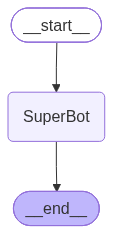

In [ ]:
graph = StateGraph(State)
## node
graph.add_node("SuperBot", superbot)

##Edges
graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)

graph_builder=graph.compile()
graph_builder

In [41]:
graph_builder.invoke({"messages":["Hello, how are you?"]})

{'messages': [HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='9376d9d8-d12e-4bb9-b8a5-9cda468aa991'),
  AIMessage(content="Hello! I'm doing well, thank you for asking. How are you doing today? Is there anything specific I can help you with?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 18, 'total_tokens': 47, 'completion_time': 0.055741354, 'completion_tokens_details': None, 'prompt_time': 0.001180613, 'prompt_tokens_details': None, 'queue_time': 0.171108711, 'total_time': 0.056921967}, 'model_name': 'Qwen/Qwen3.8-27B', 'system_fingerprint': 'fp_fea14bdc83', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a19218-1c61-7630-864e-81b2364597f9-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 18, 'output_tokens': 29, 'total_tokens': 47})]}

## Streaming response

In [43]:
for event in graph_builder.stream({"messages":["Hello, tell me recent news?"]}):
    print(event)

{'SuperBot': {'messages': [AIMessage(content='Hello! As an AI assistant, I do not have access to real-time information or live news feeds. My knowledge is based on data up to my last training update, so I cannot tell you what is happening in the world right now.\n\nFor the most recent and accurate news, I recommend checking reliable news sources such as major international news agencies (e.g., Reuters, AP), local news outlets, or trusted digital news platforms.\n\nIs there a specific topic or past event you’d like to discuss? I’d be happy to provide background information or context on a wide range of subjects.', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 120, 'prompt_tokens': 19, 'total_tokens': 139, 'completion_time': 0.236235224, 'completion_tokens_details': None, 'prompt_time': 0.001412697, 'prompt_tokens_details': None, 'queue_time': 0.503862492, 'total_time': 0.237647921}, 'model_name': 'Qwen/Qwen3.8-27B', 'system_fingerprint': 'fp_c7e30c203c', 